# Getting started

> Plan two sampling rounds on a simulated contamination map

In this tutorial you plan two sampling rounds over a simulated map of soil contamination. The map is the ground truth. You emulate each field measurement by reading the value of the map at the sample location.

You work through these steps:

1. Split the area into a 10 x 10 grid of simulated administrative units with `gridder`.
2. In Round I, rank the units by sampling priority from prior knowledge alone, with `PriorCB` and an `Optimizer`.
3. Split the sampling budget across the units by rank with `rank_to_sample`.
4. Pick sample locations in each unit with a `Sampler`, then emulate the measurements with a `DataCollector`.
5. In Round II, compute the state of each unit from those measurements and rank the units again.

In [ ]:
#| hide
import warnings
warnings.filterwarnings('ignore')

%load_ext autoreload
%autoreload 2

## Imports

In [ ]:
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd

from trufl.utils import gridder
from trufl.sampler import Sampler, rank_to_sample
from trufl.collector import DataCollector
from trufl.callbacks import (State, MaxCB, MinCB, StdCB, CountCB, MoranICB, PriorCB)
from trufl.optimizer import Optimizer


red, black = '#BF360C', '#263238'

## Our simulated ground truth

The assumed ground truth reveals a typical spatial pattern of contaminant such as `Cs137` after a nuclear accident for instance:

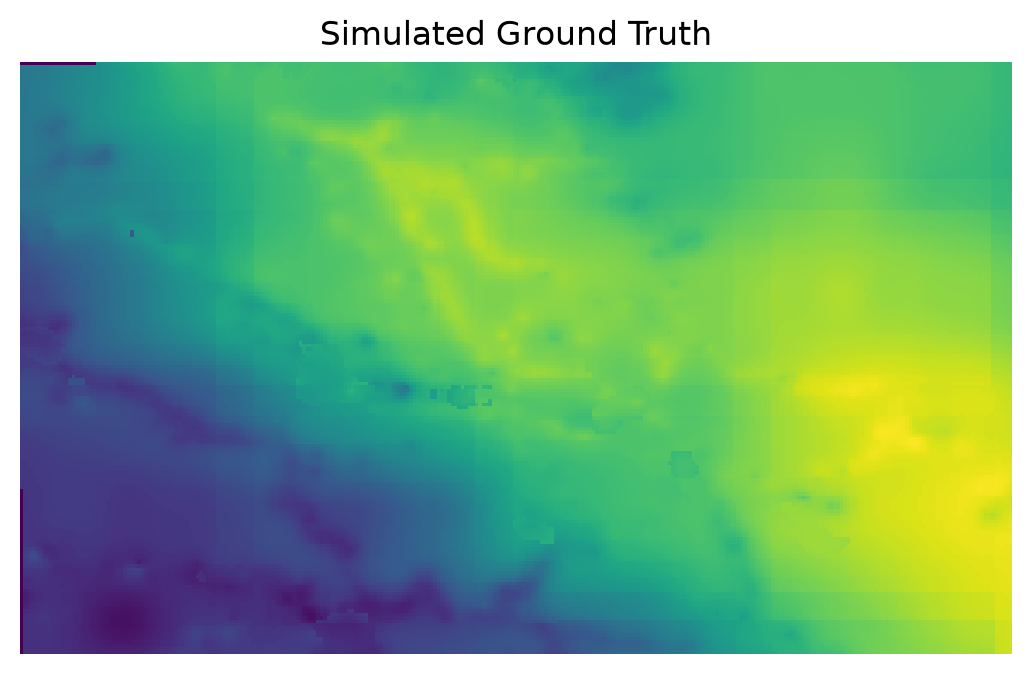

In [ ]:
fname_raster = '../files/ground-truth-01-4326-simulated.tif'
with rasterio.open(fname_raster) as src:
    plt.axis('off')
    plt.imshow(src.read(1))
    plt.title('Simulated Ground Truth')

## Simulate administrative units

The sampling strategy will be determined on a per-grid-cell basis within the administrative unit. We define below a 10 x 10 grid over the area of interest:

In [ ]:
gdf_grid = gridder(fname_raster, nrows=10, ncols=10)
gdf_grid.head()

,geometry
loc_id,
0,"POLYGON ((-1.2083 43.2695, -1.2083 43.26042, -..."
1,"POLYGON ((-1.2083 43.27858, -1.2083 43.2695, -..."
2,"POLYGON ((-1.2083 43.28766, -1.2083 43.27858, ..."
3,"POLYGON ((-1.2083 43.29673, -1.2083 43.28766, ..."
4,"POLYGON ((-1.2083 43.30581, -1.2083 43.29673, ..."


:::{.callout-tip}

Note how each administrative unit is uniquely identified by its `loc_id`.

:::

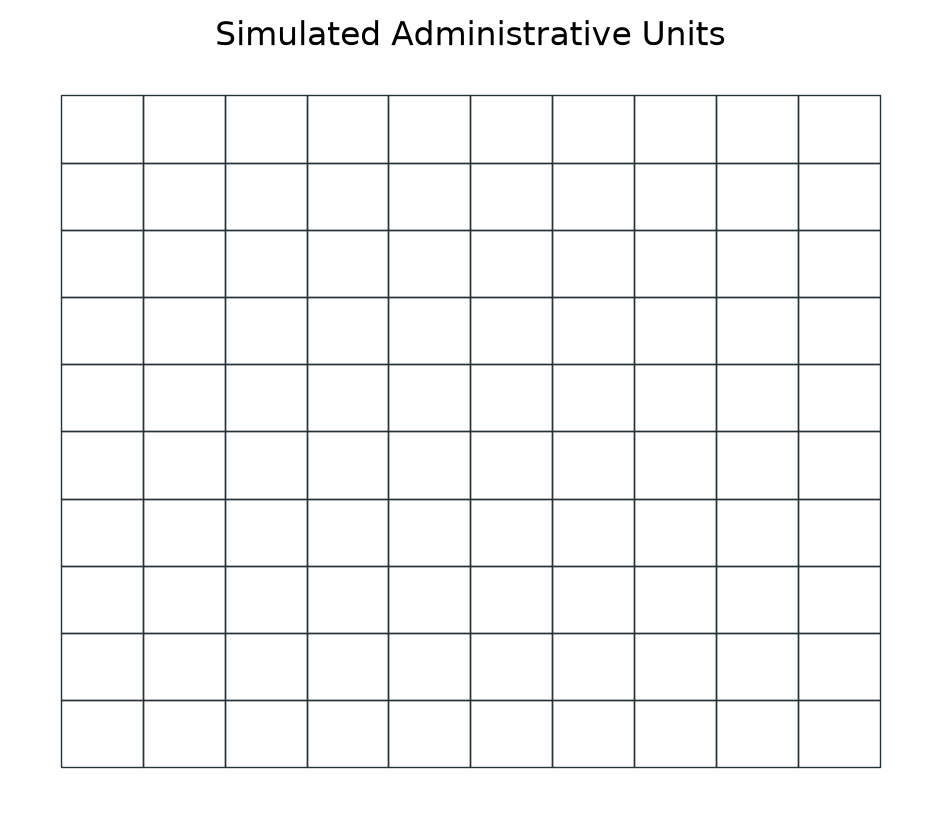

In [ ]:
gdf_grid.boundary.plot(color=black, lw=0.5)
plt.axis('off')
plt.title('Simulated Administrative Units');

## Round I: Optimize sampling based on prior at $t_0$

### What prior knowledge do we have?

At the initial time $t_0$, data sampling has not yet begun, but we can often **leverage existing prior knowledge of our phenomenon** of interest to inform our sampling strategy/policy. In the context of nuclear remediation, this prior knowledge can often be obtained through mobile surveys, such as airborne or carborne surveys, which can provide a **coarse estimation** of soil contamination levels.

In the example below, we **simulate prior information** about the soil property of interest by **calculating the average value of the property over each grid cell**.

At this stage, we have no measurements, so we simply create an empty [Geopandas GeoDataFrame](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html). 

In [ ]:
samples_t0 = gpd.GeoDataFrame(index=pd.Index([], name='loc_id'), 
                              geometry=None, data={'value': None})

:::{.callout-tip}

We need to set an index `loc_id` and have a `geometry` and `value` columns.

:::

Now we get/"sense" the state of our grid cells based on the simulated prior (Mean over each grid cell `PriorCB`):

In [ ]:
state = State(samples_t0, gdf_grid, cbs=[PriorCB(fname_raster)])

# You have to call the instance
state_t0 = state(); state_t0.head()

,Prior
loc_id,
0,0.108520
1,0.133123
2,0.161802
3,0.195281
4,0.213253


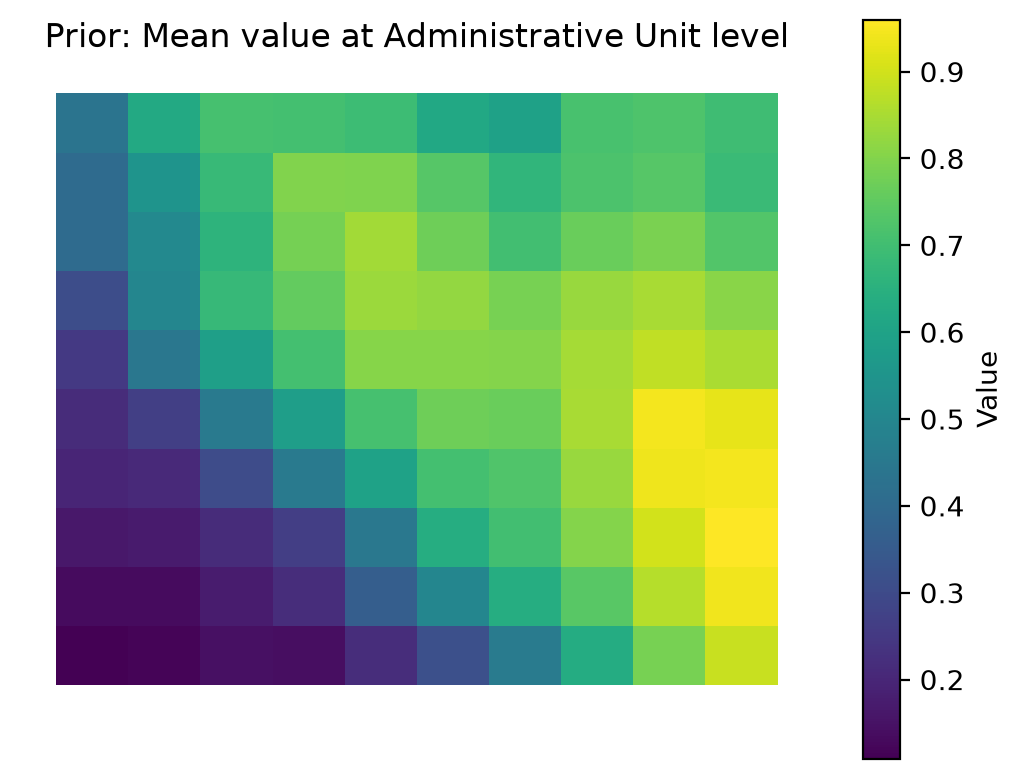

In [ ]:
gdf_grid.join(state_t0, how='left').plot(column='Prior',
                                         cmap='viridis', 
                                         legend_kwds={'label': 'Value'}, 
                                         legend=True)
plt.axis('off')
plt.title('Prior: Mean value at Administrative Unit level');

:::{.callout-tip}

We get the `Prior` for each individual `loc_id` (here only the first 5 shown). The current `State` is only composed of a single `PriorCB` variable but can include many more variables as we will see below. 

:::

### Sampling priority ranks

In [ ]:
benefit_criteria = [True]
optimizer = Optimizer(state=state_t0)
df_rank = optimizer.get_rank(is_benefit_x=benefit_criteria, w_vector = [1],  
                             n_method=None, c_method = None, 
                             w_method=None, s_method="CP")

df_rank.head()

,rank
loc_id,
92,1
93,2
84,3
91,4
83,5


:::{.callout-tip}
[How trufl ranks areas](../explanation/02_ranking.ipynb) explains how the `Optimizer` turns criteria and weights into ranks.
:::


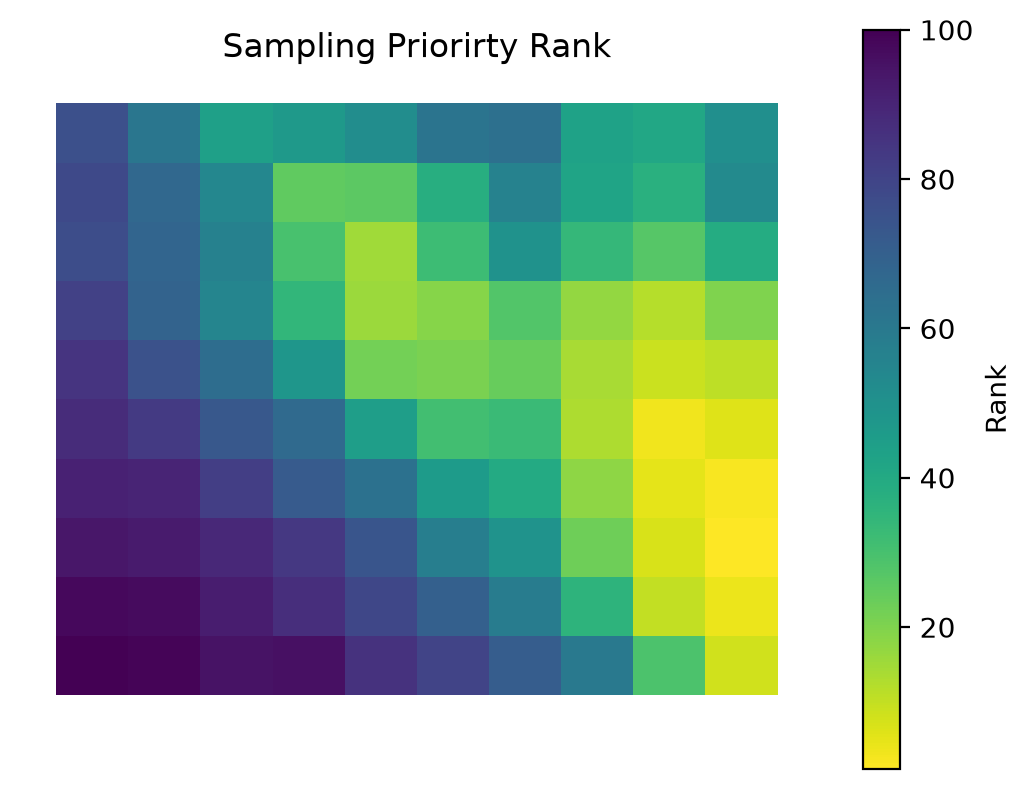

In [ ]:
gdf_grid.join(df_rank, how='left').plot(column='rank',
                                        cmap='viridis_r', 
                                        legend_kwds={'label': 'Rank'}, 
                                        legend=True)
plt.axis('off')
plt.title('Sampling Priorirty Rank');

### Informed random sampling

:::{.callout-tip}

It's worth noting that in the absence of any prior knowledge, a uniform sampling strategy over the area of interest may be used. However, this approach may not be the most efficient use of the available data collection and analysis budget.

:::

Based on the **ranks (sampling priority)** calculated by the `Optimizer` and given sampling **budget**, let's calculate the number of samples to be collected for each administrative unit (`loc_id`). **Different sampling policies** can be used (Weighted, Quantiles, ...):

In [ ]:
budget_t0 = 600
n = rank_to_sample(df_rank['rank'].sort_index().values, 
                   budget=budget_t0, min=1, policy="quantiles"); n

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  4,  4,
        4,  4,  4,  1,  1,  1,  1,  4,  4,  4,  4,  4,  7,  1,  1,  1,  4,
        4,  7,  7,  7, 12,  7,  1,  1,  4,  4,  7, 12, 12, 12,  7,  4,  1,
        4,  4,  7,  7, 12, 12,  7,  7,  4,  4,  4,  7,  7,  7, 12,  7,  7,
        4,  4,  4,  7, 12, 12, 12, 12, 12,  7,  7,  7,  7, 12, 12, 12, 12,
       12, 12,  7,  7,  7, 12, 12, 12, 12, 12, 12, 12,  7,  4,  4])

We can now decide where to sample based on this sampling schema:

                                geometry
loc_id                                  
0       MULTIPOINT ((-1.20846 43.26142))
1       MULTIPOINT ((-1.21991 43.27015))
2       MULTIPOINT ((-1.20838 43.28074))
3       MULTIPOINT ((-1.21735 43.28959))
4       MULTIPOINT ((-1.20944 43.30343))


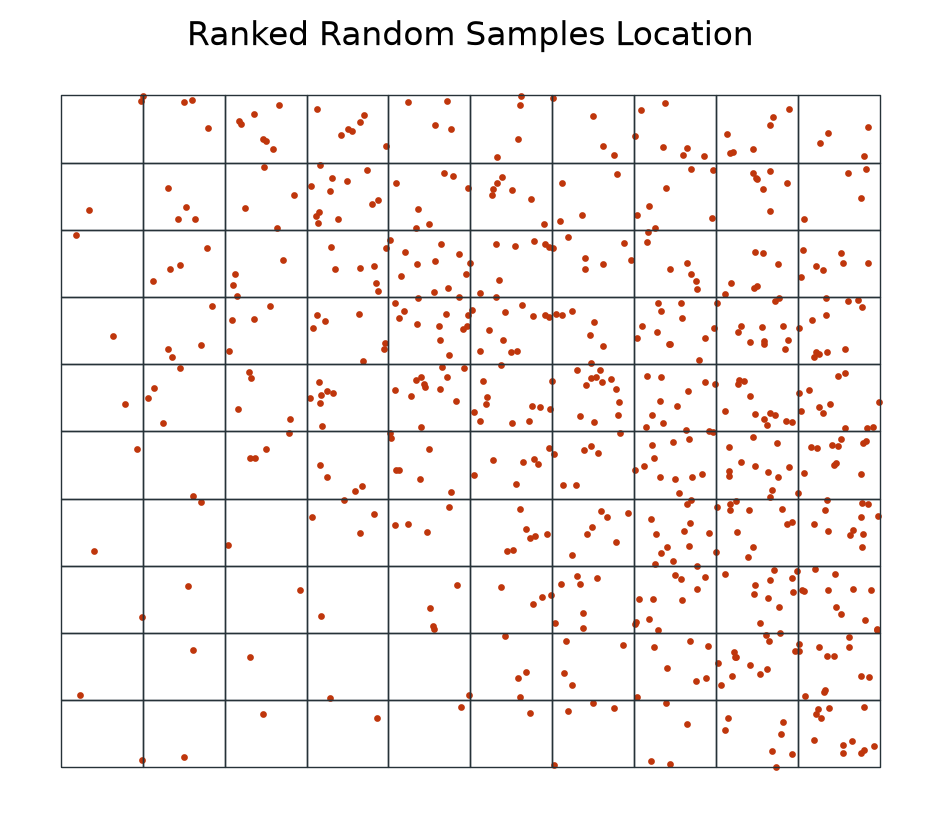

In [ ]:
sampler = Sampler(gdf_grid)
sample_locs_t0 = sampler.sample(n, method='uniform')

print(sample_locs_t0.head())
ax = sample_locs_t0.plot(markersize=2, color=red)

gdf_grid.boundary.plot(color=black, lw=0.5, ax=ax)
plt.axis('off')
plt.title('Ranked Random Samples Location');

### Emulating measurement campaign

The data collector collects measurements at the random sampling locations in the field. In our case, we emulate this process by extracting measurements from the provided raster file.

"Measuring" variable of interest from a given raster:

                         geometry     value
loc_id                                     
0       POINT (-1.20846 43.26142)  0.089033
1       POINT (-1.21991 43.27015)  0.136715
2       POINT (-1.20838 43.28074)  0.154431
3       POINT (-1.21735 43.28959)  0.179844
4       POINT (-1.20944 43.30343)  0.228972


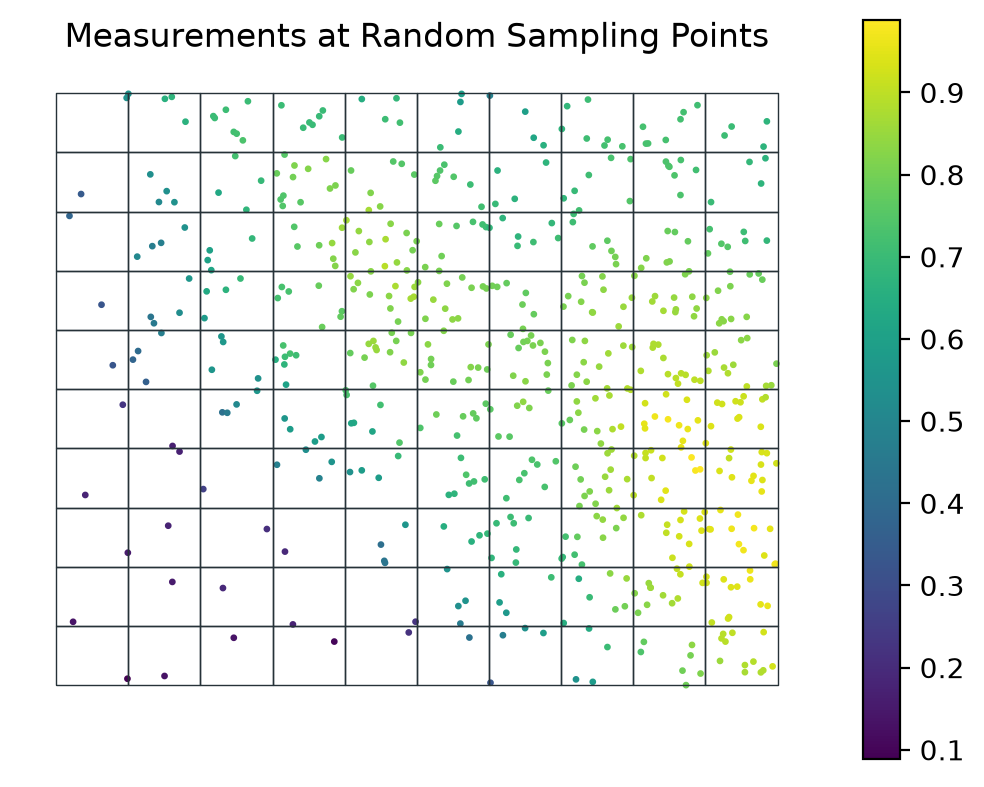

In [ ]:
dc_emulator = DataCollector(fname_raster)
measurements_t0 = dc_emulator.collect(sample_locs_t0)

print(measurements_t0.head())
ax = measurements_t0.plot(column='value', s=2, legend=True)
gdf_grid.boundary.plot(color=black, lw=0.5, ax=ax);
plt.axis('off')
plt.title('Measurements at Random Sampling Points');

This marks the **end of our initial measurement efforts**, based on our prior knowledge of the phenomenon. **Going forward, we can use the additional insights gained during this phase** to enhance our future measurements.

## Round II: Optimize sampling with additional insights at $t_1$

For each administrative unit, we now have additional knowledge acquired during the previous campaign, in addition to our prior knowledge. **In the current round**, the **optimization** of the sampling will be **carried out based on** the **maximum**, **minimum**, **standard Deviation**, **number of measurements** already conducted, our **prior knowledge**, and an estimate of the **presence of spatial trends** or spatial correlations (Moran's I).

:::{.callout-tip}

It's worth noting that you can use any quantitative or qualitative secondary geographical information as a variable in the state, such as population, whether any previous remediation actions have taken place, the economic impact of the contamination, and so on.

:::

### Getting administrative units new state

In [ ]:
state = State(measurements_t0, gdf_grid, cbs=[
    MaxCB(), MinCB(), StdCB(), CountCB(), MoranICB(k=5), PriorCB(fname_raster)])

In [ ]:
state().head()

,Max,Min,Standard Deviation,Count,Moran.I,Prior
loc_id,,,,,,
0,0.089033,0.089033,0.0,1,NaN,0.108520
1,0.136715,0.136715,0.0,1,NaN,0.133123
2,0.154431,0.154431,0.0,1,NaN,0.161802
3,0.179844,0.179844,0.0,1,NaN,0.195281
4,0.228972,0.228972,0.0,1,NaN,0.213253


:::{.callout-tip}

The **Moran's I index** is a statistical method used to determine if there is a **spatial correlation/trend** within each area of interest. For example, a **random field** would have a **Moran's I index close to 0**, while a clear **gradient of low to high values**, such as from south to north, would be characterized by a **Moran's I index close to 1**.

:::

### Finding optimal number of samples to be collected

1. We first decide if each variable of the State are to maximize (**benefit**) or minimize (**cost**):

In [ ]:
benefit_criteria = [True, True, True, False, False, True]

2. Then assign an **importance weight** to each of the variable of the `State` (`Min`, `Max`, ...):

In [ ]:
optimizer = Optimizer(state=state())
df_rank = optimizer.get_rank(is_benefit_x=benefit_criteria, 
                             w_vector = [0.2, 0.1, 0.1, 0.2, 0.2, 0.2],  
                             n_method="LINEAR1", c_method=None, w_method=None, s_method="CP")

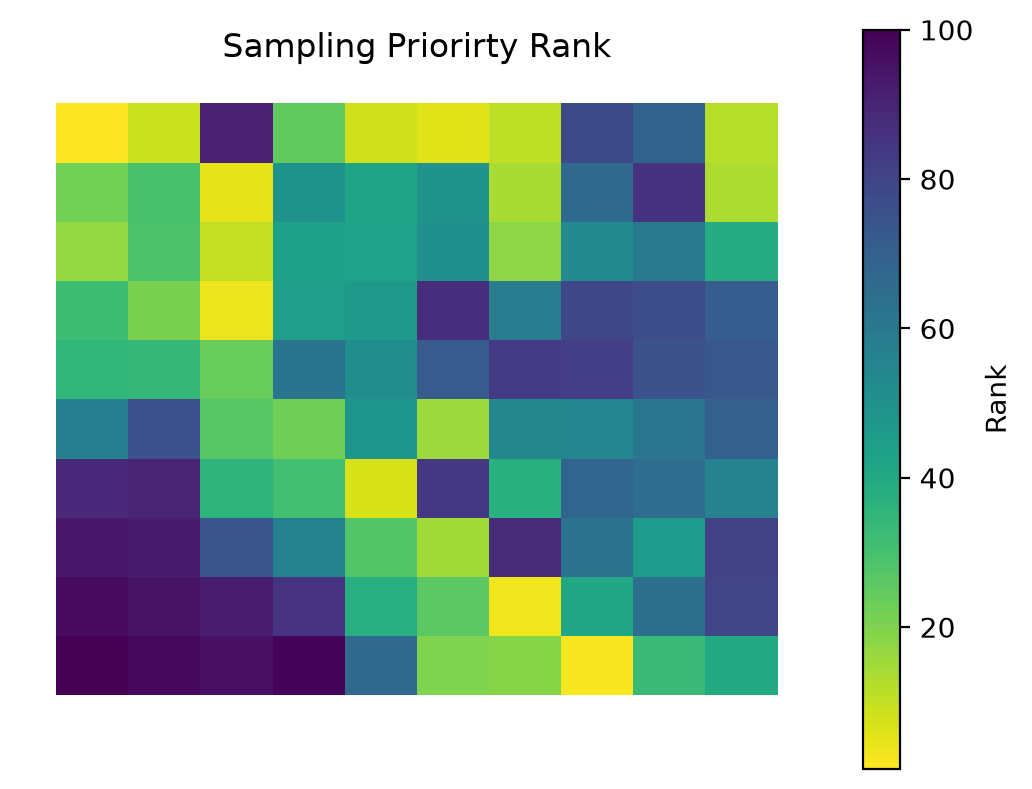

In [ ]:
gdf_grid.join(df_rank, how='left').plot(column='rank',
                                        cmap='viridis_r', 
                                        legend_kwds={'label': 'Rank'}, 
                                        legend=True)
plt.axis('off')
plt.title('Sampling Priorirty Rank');

In [ ]:
df_rank.head()

,rank
loc_id,
9,1
70,2
61,3
26,4
28,5


Based on this rank we can again: 
1. based on the **ranks (sampling priority)** and given sampling **budget**, calculate the number of samples to be collected for each administrative unit and carry out **random sampling**;
2. **perform** the random **sampling**;
3. and **carry out** the **measurements**.

### Informed random sampling

In [ ]:
budget_t1 = 400
n = rank_to_sample(df_rank['rank'].sort_index().values, 
                   budget=budget_t1, min=1, policy="quantiles"); n

array([1, 1, 1, 1, 3, 4, 4, 8, 8, 8, 1, 1, 1, 1, 1, 4, 8, 4, 4, 8, 1, 1,
       3, 4, 4, 8, 8, 8, 8, 1, 1, 1, 3, 4, 8, 3, 4, 4, 4, 8, 3, 4, 4, 8,
       4, 3, 4, 4, 4, 8, 8, 4, 8, 1, 8, 3, 1, 3, 4, 8, 8, 8, 1, 4, 3, 1,
       3, 8, 8, 8, 8, 4, 3, 3, 3, 1, 1, 3, 3, 1, 4, 3, 4, 3, 3, 3, 1, 3,
       1, 3, 4, 1, 1, 3, 3, 3, 3, 4, 8, 8])

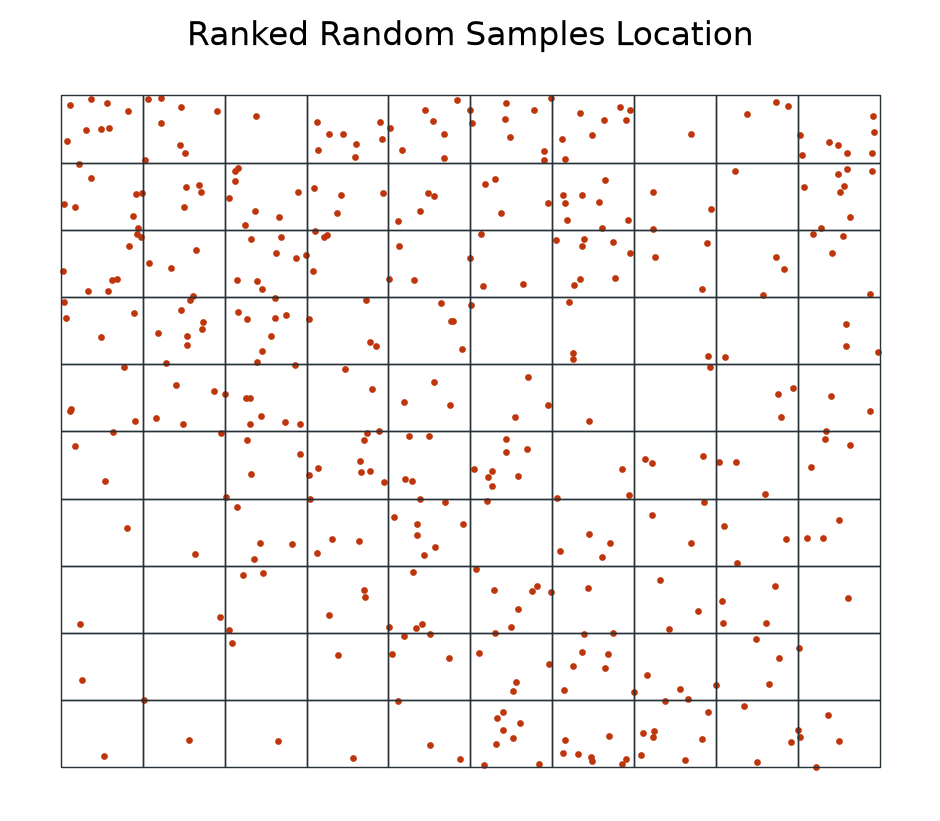

In [ ]:
sampler = Sampler(gdf_grid)
sample_locs_t1 = sampler.sample(n, method='uniform')

ax = sample_locs_t1.plot(markersize=2, color=red)
gdf_grid.boundary.plot(color=black, lw=0.5, ax=ax)
plt.axis('off')
plt.title('Ranked Random Samples Location');

### Second measurement campaign

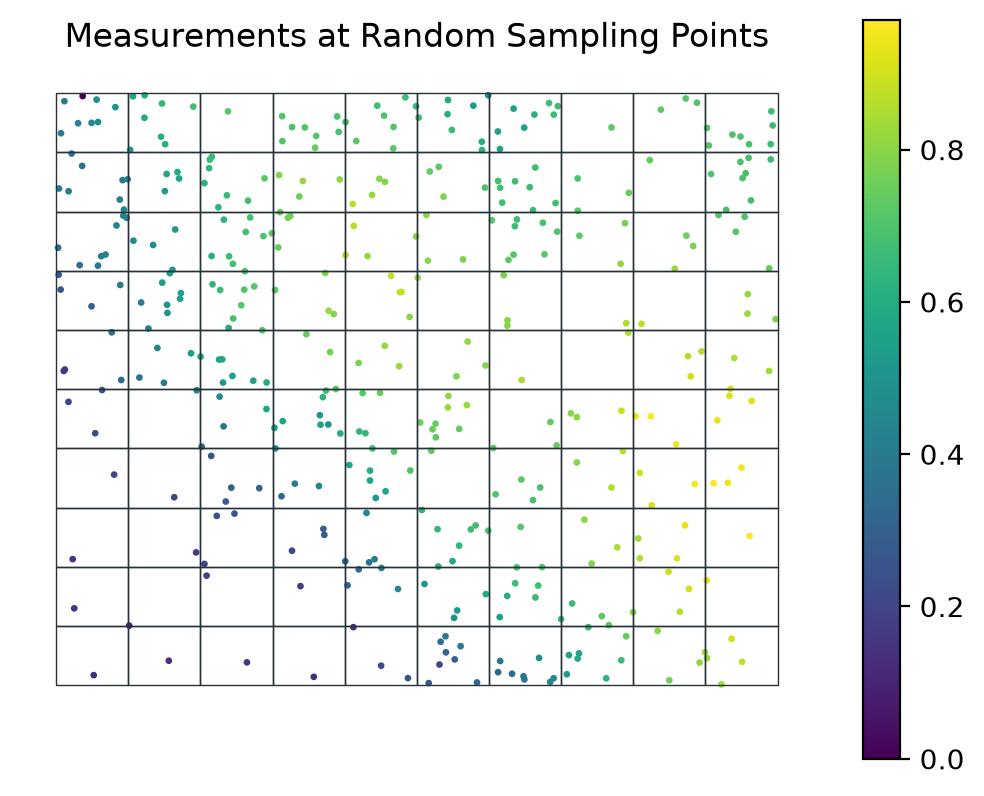

In [ ]:
dc_emulator = DataCollector(fname_raster)
measurements_t1 = dc_emulator.collect(sample_locs_t1)

ax = measurements_t1.plot(column='value', s=2, legend=True)
gdf_grid.boundary.plot(color=black, lw=0.5, ax=ax);
plt.axis('off')
plt.title('Measurements at Random Sampling Points');

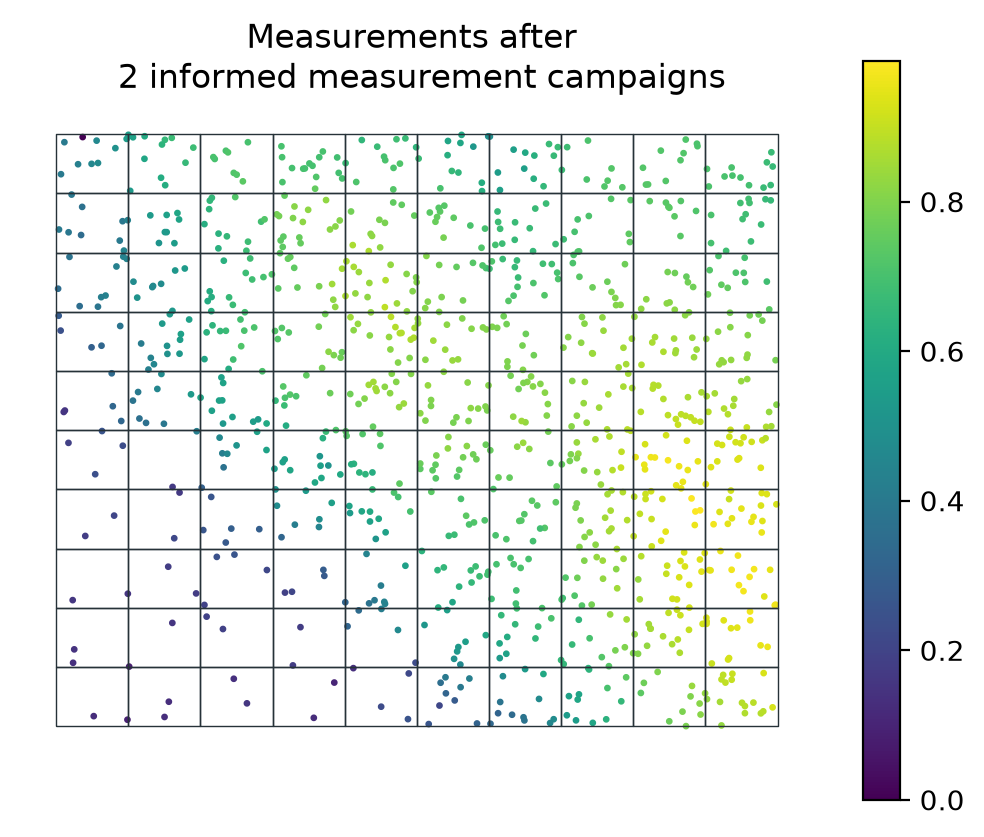

In [ ]:
measurements_sofar = pd.concat([measurements_t0, measurements_t1])

ax = measurements_sofar.plot(column='value', s=2, legend=True)
gdf_grid.boundary.plot(color=black, lw=0.5, ax=ax);
plt.axis('off')
plt.title('Measurements after \n 2 informed measurement campaigns');